<a href="https://colab.research.google.com/github/Pra-vhat/AI-Bootcamp/blob/main/EDA_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Loading Dataset

In [ ]:
'''
import os

os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""

# Verify that the Kaggle API can communicate properly
!kaggle datasets list
'''


'\nimport os\n\nos.environ[\'KAGGLE_USERNAME\'] = ""\nos.environ[\'KAGGLE_KEY\'] = ""\n\n# Verify that the Kaggle API can communicate properly\n!kaggle datasets list\n'

In [ ]:
'''

# Download the  dataset
!kaggle datasets download -d fedesoriano/stroke-prediction-dataset

# Unzip the files
!unzip stroke-prediction-dataset.zip
'''

'\n\n# Download the  dataset\n!kaggle datasets download -d fedesoriano/stroke-prediction-dataset\n\n# Unzip the files\n!unzip stroke-prediction-dataset.zip\n'

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [ ]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


2. Data Overview

In [ ]:
df.shape

(5110, 12)

12 parameters including id, gender, age...
5110 sample size

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
df.describe(include = 'object')

,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


In [ ]:
df.describe(include = 'all')

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


Understanding each of the features (columns)

In [ ]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

4. Data Quality Assessment

4(2) Missing values

In [ ]:
#missing values
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


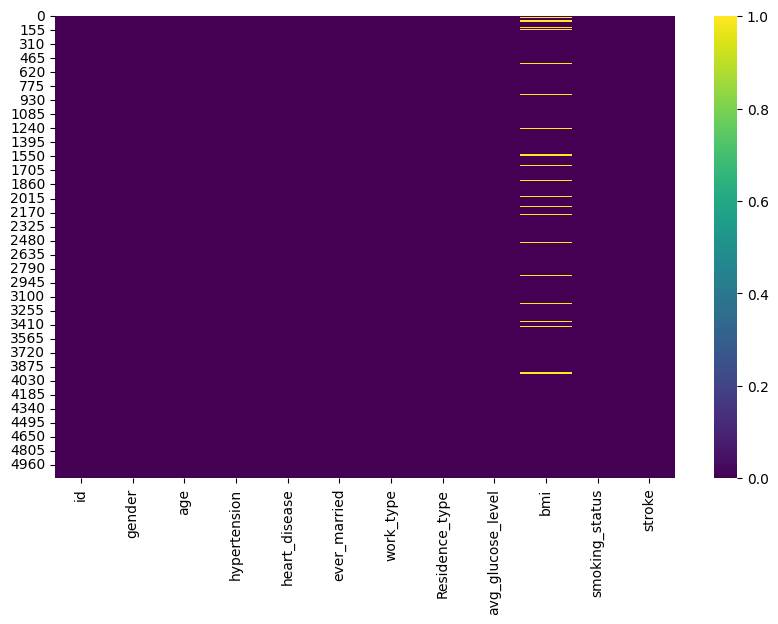

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(),cmap='viridis')
plt.show()

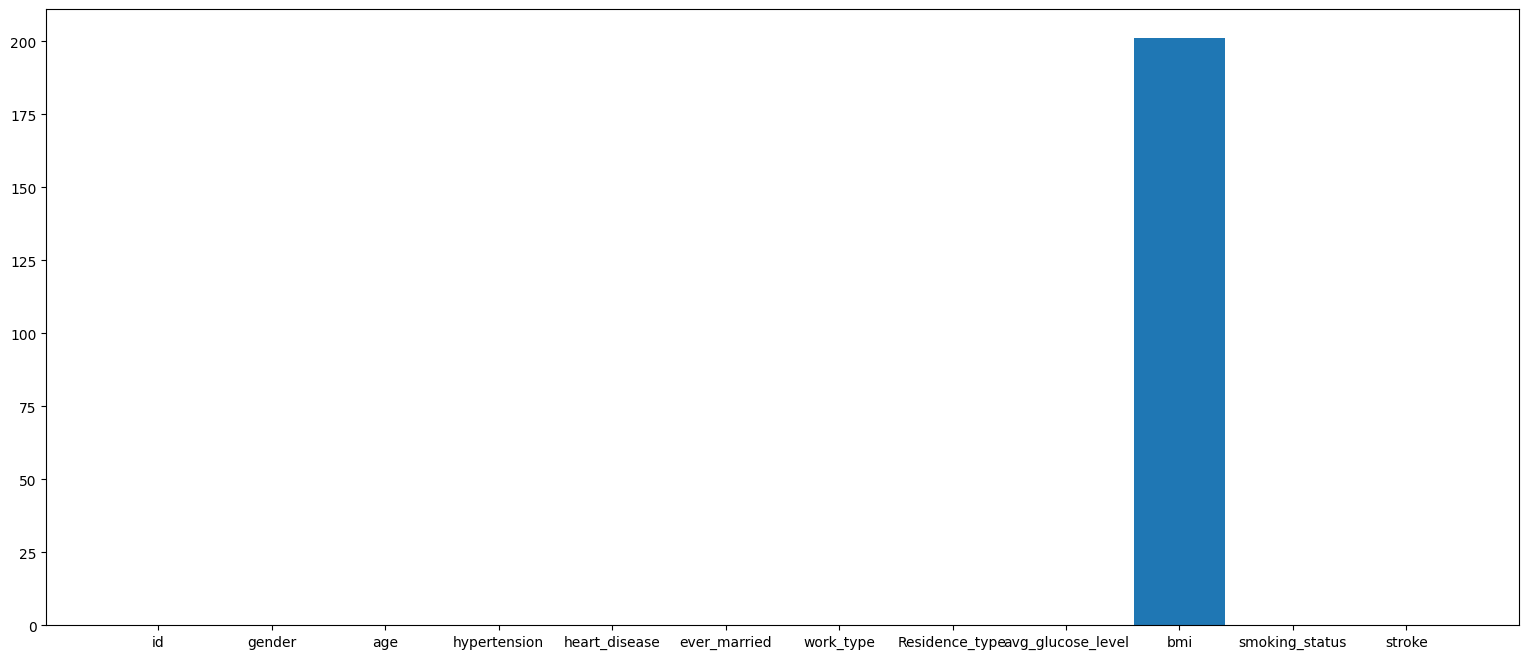

In [ ]:
plt.figure(figsize=(19, 8))
plt.bar(df.columns,df.isnull().sum())
plt.show()

~200 missing BMI values. Total is 5110. Not a big part is missing, it remains to be seen

4(2) Duplicate Values

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
id,5110
gender,3
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3979
bmi,418


5. Univariate Analysis

What do I want to visualize?
- id? No
- gender? only to see the distribution, yes
- age? Yes, it should be fairly important. I suspect older people are more susceptible to strokes
- hypertension? yes, hypertension should be a fair indicator with age
- heart_disease? yes.
- ever_married? perhaps? i am not sure about this
- work_type? definitely
- residence_type? Perhaps?
- avg_glucose_level? yes
- bmi? yes
- smoking status? definitely

5(1) Numeric Variables: age, avg_glucose_level, bmi

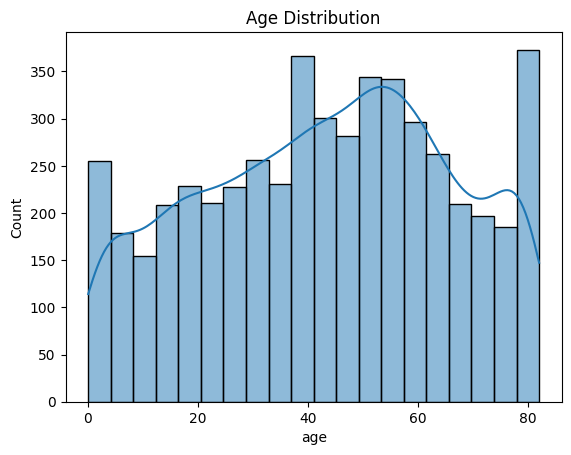

In [ ]:

sns.histplot(df["age"], kde=True)
plt.title("Age Distribution")
plt.show()

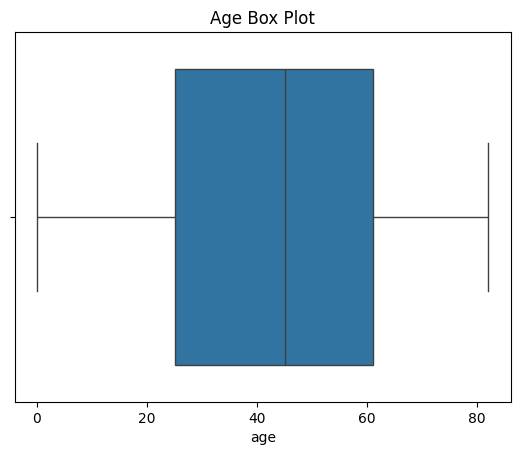

In [ ]:
sns.boxplot(df["age"].dropna(), orient="h")
plt.title("Age Box Plot")
plt.show()

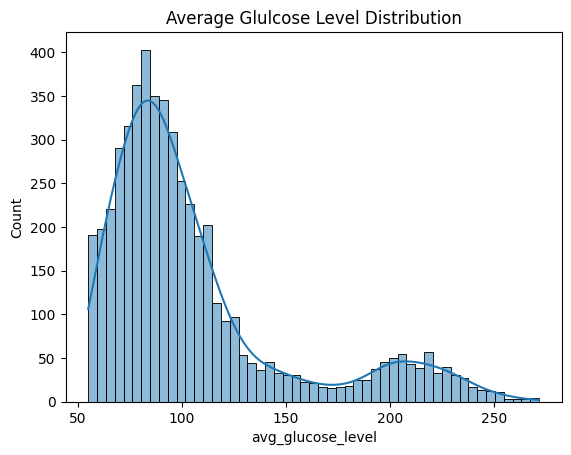

In [ ]:
sns.histplot(df["avg_glucose_level"], kde=True)
plt.title("Average Glulcose Level Distribution")
plt.show()

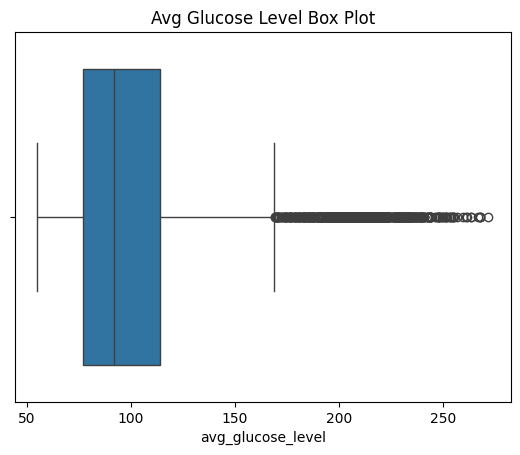

In [ ]:
sns.boxplot(df["avg_glucose_level"].dropna(), orient="h")
plt.title("Avg Glucose Level Box Plot")
plt.show()

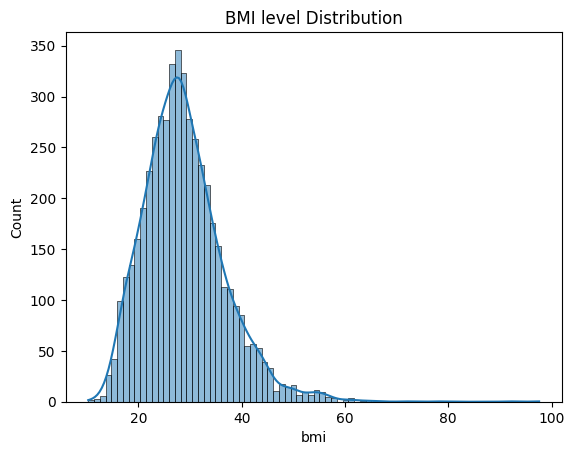

In [ ]:
sns.histplot(df["bmi"], kde=True)
plt.title("BMI level Distribution")
plt.show()

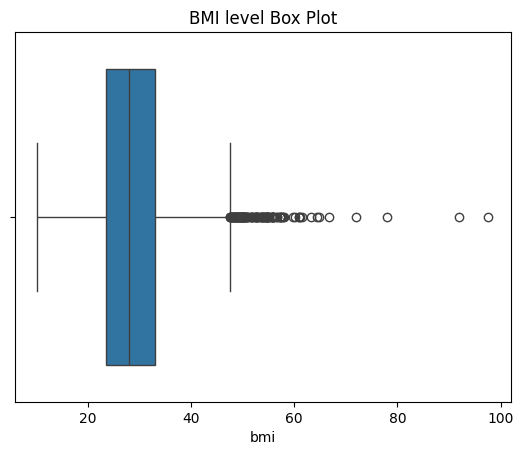

In [ ]:
sns.boxplot(df["bmi"].dropna(), orient="h")
plt.title("BMI level Box Plot")
plt.show()

Categorical data: gender, hypertension, heart_disease, ever_married, worktype, residence_type, smoking_status, stroke

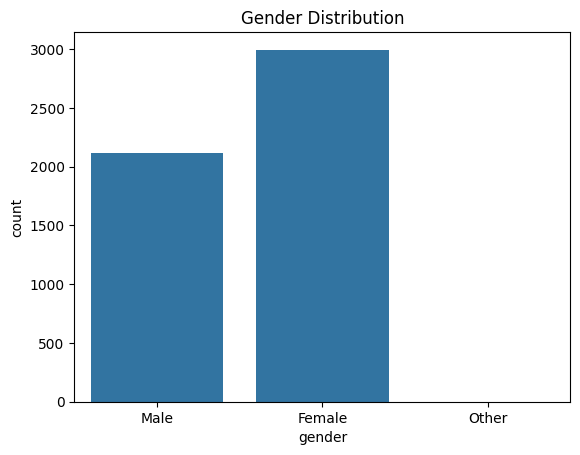

In [ ]:
sns.countplot(data = df, x = "gender")
plt.title("Gender Distribution")
plt.show()

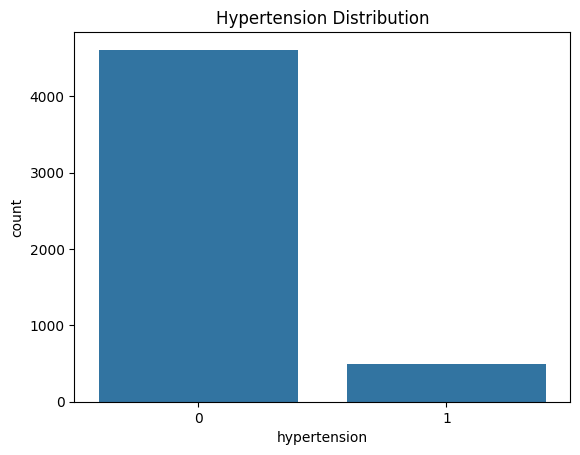

In [ ]:
sns.countplot(data = df, x = "hypertension")
plt.title("Hypertension Distribution")
plt.show()

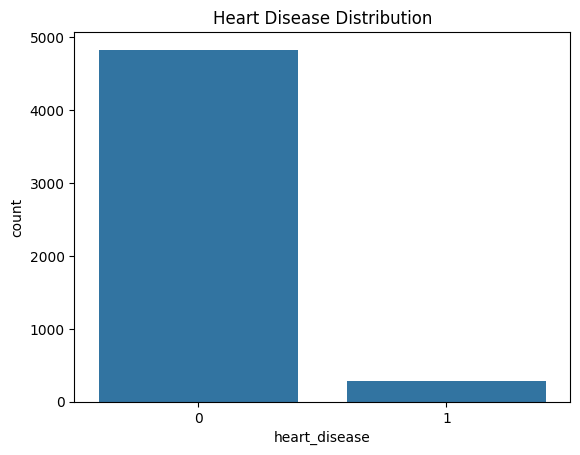

In [ ]:
#heart_disease
sns.countplot(data = df, x = "heart_disease")
plt.title("Heart Disease Distribution")
plt.show()

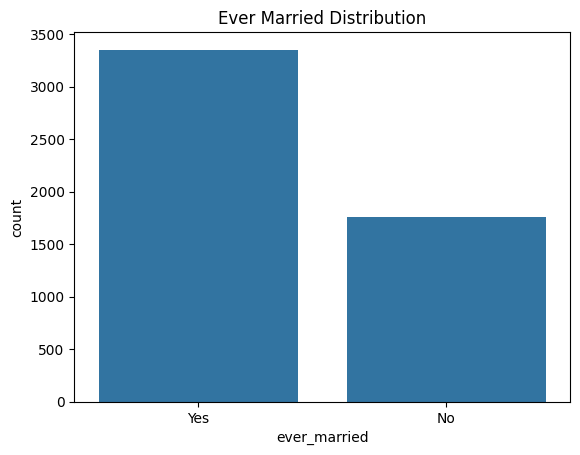

In [ ]:
#ever_married
sns.countplot(data = df, x = "ever_married")
plt.title("Ever Married Distribution")
plt.show()

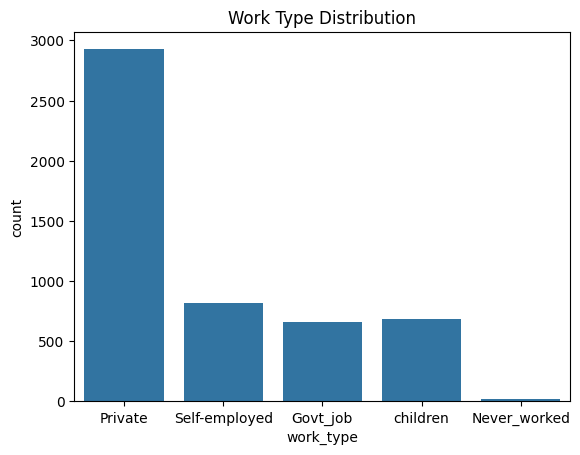

In [ ]:
sns.countplot(data = df, x = "work_type")
plt.title("Work Type Distribution")
plt.show()

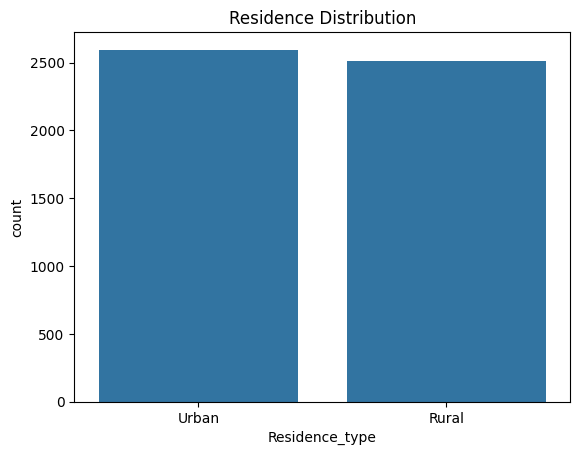

In [ ]:
sns.countplot(data = df, x = "Residence_type")
plt.title("Residence Distribution")
plt.show()

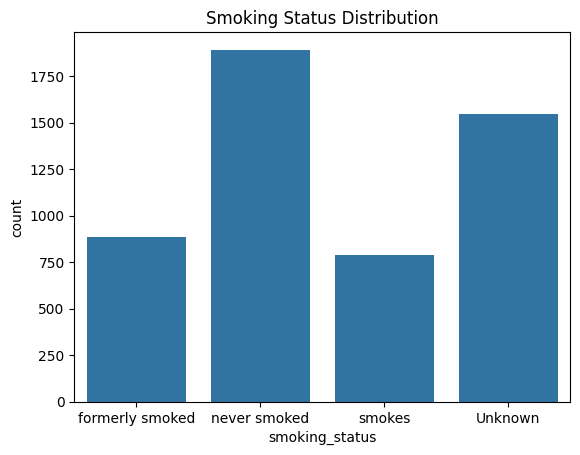

In [ ]:
sns.countplot(data = df, x = "smoking_status")
plt.title("Smoking Status Distribution")
plt.show()

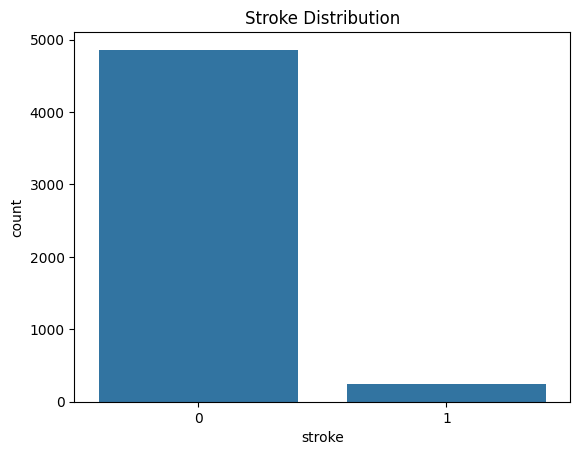

In [ ]:
#stroke
sns.countplot(data = df, x = "stroke")
plt.title("Stroke Distribution")
plt.show()

6. Bivariate Analysis
  Investigate relationship between two or more aspects

  ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke']


In [ ]:
# numeric data types are age, avg_glucose_level, bmi

bins = [0, 12, 19, 39, 59, 100]
labels = ['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior']

df['age_bin'] = pd.cut(df['age'].dropna(), bins=bins, labels=labels)

bins = [0, 25, 50, 75, 100, float('inf')]
labels = ['Low', 'Medium', 'High', 'Very High', 'Extremely High']
df['avg_glucose_level_bin'] = pd.cut(df['avg_glucose_level'].dropna(), bins=bins, labels=labels)


bins = [0, 18.5, 24.9, 29.9, 34.9, 100]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese Class I', 'Obese Class II']
df['bmi_bin'] = pd.cut(df['bmi'].dropna(), bins=bins, labels=labels)

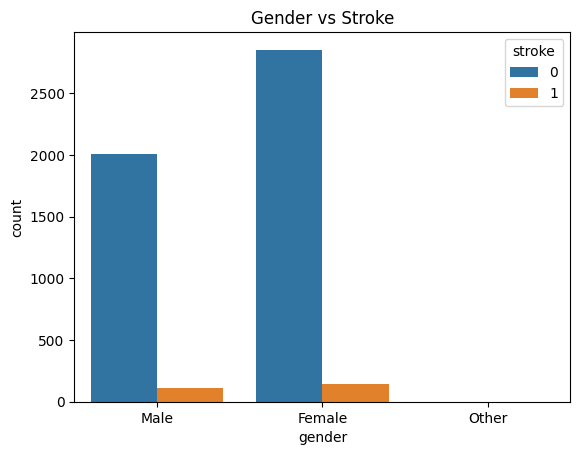

In [ ]:
sns.countplot(data = df, x = "gender", hue = "stroke")
plt.title("Gender vs Stroke")
plt.show()

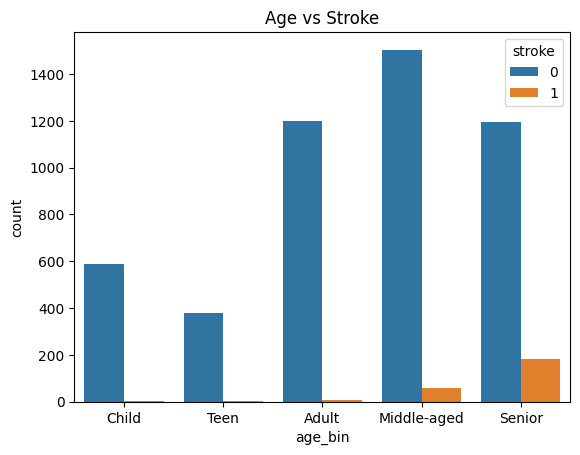

In [ ]:
sns.countplot(data = df, x = "age_bin", hue = "stroke")
plt.title("Age vs Stroke")
plt.show()

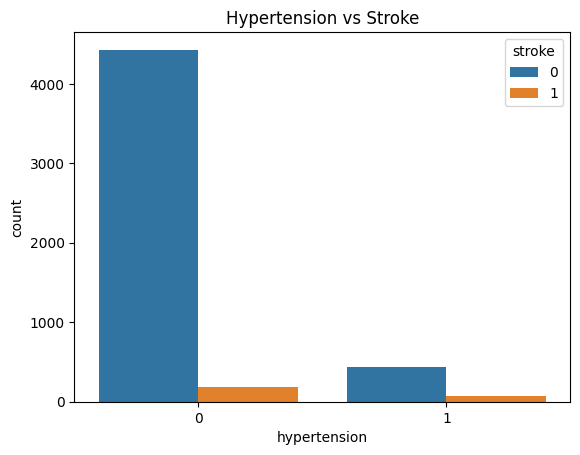

In [ ]:
sns.countplot(data = df, x = "hypertension", hue = "stroke")
plt.title("Hypertension vs Stroke")
plt.show()

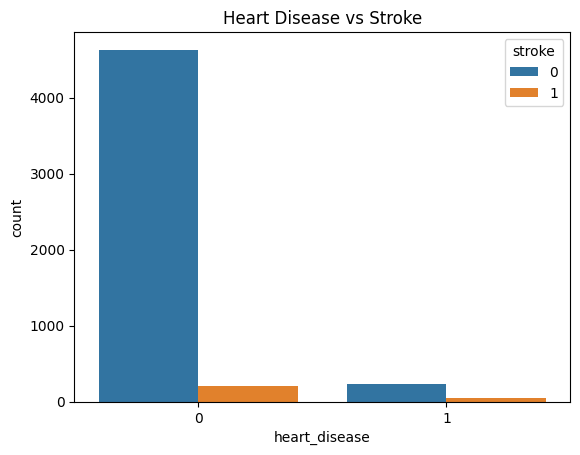

In [ ]:
sns.countplot(data = df, x = "heart_disease", hue = "stroke")
plt.title("Heart Disease vs Stroke")
plt.show()

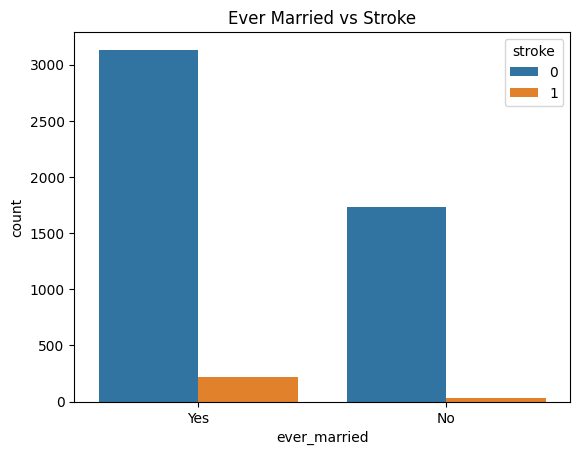

In [ ]:
sns.countplot(data = df, x = "ever_married", hue = "stroke")
plt.title("Ever Married vs Stroke")
plt.show()

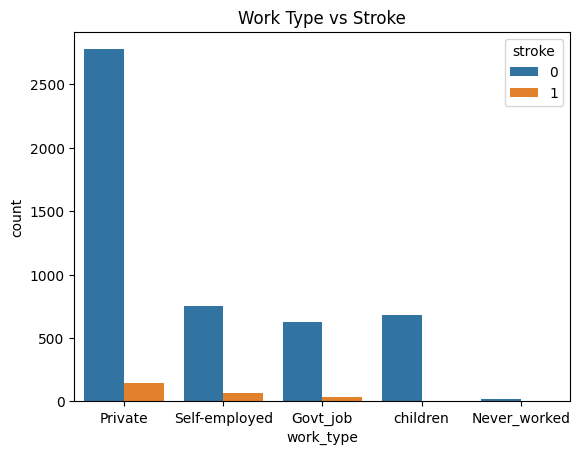

In [ ]:
sns.countplot(data = df, x = "work_type", hue = "stroke")
plt.title("Work Type vs Stroke")
plt.show()

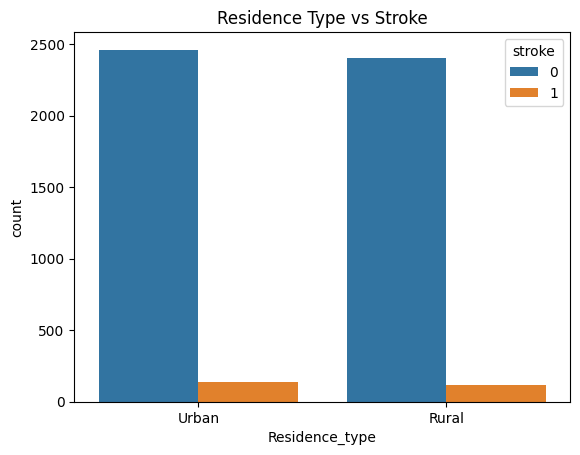

In [ ]:
sns.countplot(data = df, x = "Residence_type", hue = "stroke")
plt.title("Residence Type vs Stroke")
plt.show()

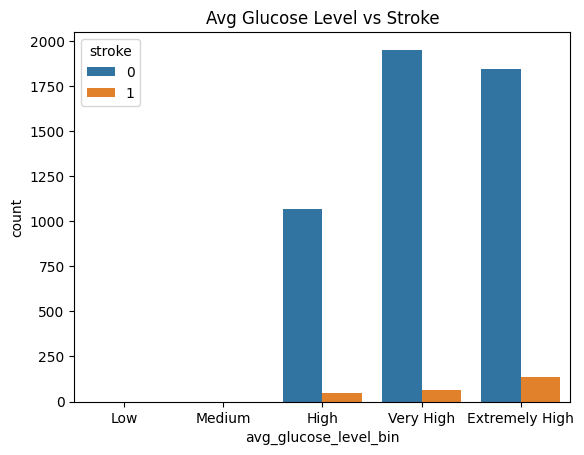

In [ ]:

sns.countplot(data = df, x = "avg_glucose_level_bin", hue = "stroke")
plt.title("Avg Glucose Level vs Stroke")
plt.show()

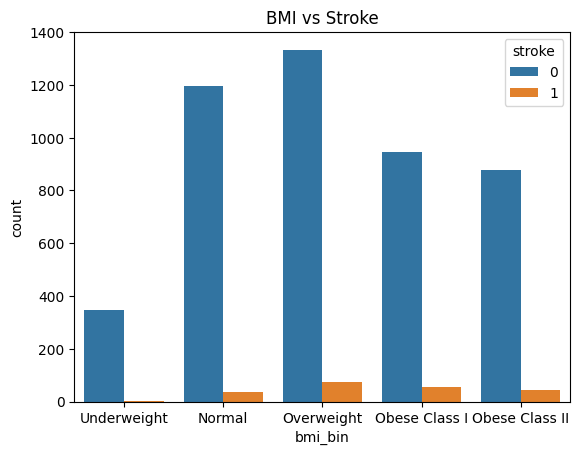

In [ ]:
sns.countplot(data = df, x = "bmi_bin", hue = "stroke")
plt.title("BMI vs Stroke")
plt.show()

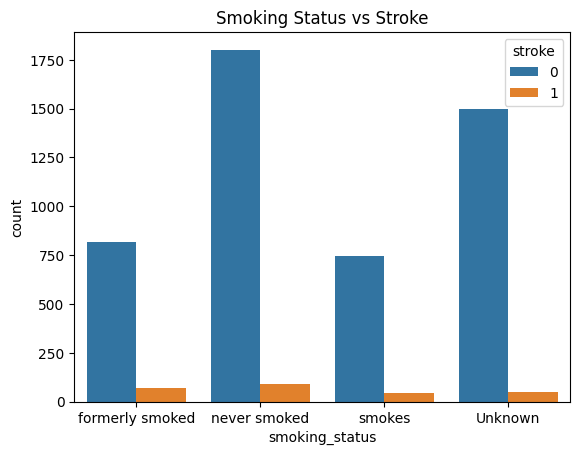

In [ ]:
sns.countplot(data = df, x = "smoking_status", hue = "stroke")
plt.title("Smoking Status vs Stroke")
plt.show()

7. Correlation:


<Axes: >

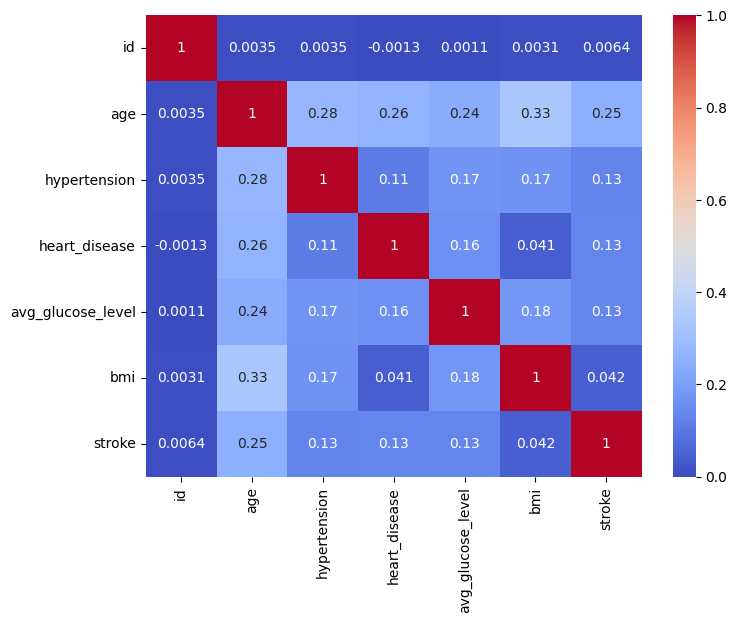

In [ ]:
import numpy as np
numeric = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))
sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm"
)

8. Conclusion

- BMI and age_class are strong predictors of stroke
- Hypertension doesn't accurately predict stroke as expected
- Residence type has almost no relation with stroke prediction
- Work type can't reliably predict stroke
- *People that were 'ever_married' are also more likely to get stroke >_<*
- gender is also less likely to predict stroke